# Lab 2 of 8 — Supervised learning I: regression, classification, and the workflow

**Course:** TEB3123 Machine Learning
**Student:** Muhammad Aqil Bazli Bin Jafni

**Goal.** Fit regression/classification pipelines, validate chronologically where needed, tune thresholds and hyperparameters, test once, and save models.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

Use one helper for numerical imputation/scaling and categorical imputation/one-hot encoding.

In [2]:
def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

## Part A — Regression: ordinary least squares versus ridge
Predict insurance charges. Compare OLS and ridge on the same features and split.

In [3]:
insurance = pd.read_csv(DATA / "medical_cost_personal_dataset.csv")
print(insurance.head())

X = insurance.drop(columns="charges")
y = insurance["charges"]
num_cols = ["age", "bmi", "children"]
cat_cols = ["sex", "smoker", "region"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


MAE gives average dollar error; RMSE emphasizes extremes; R² compares squared error with the mean-label reference.

In [4]:
fitted = {}
predictions = {}

for name, estimator in {
    "linear regression": LinearRegression(),
    "ridge": Ridge(alpha=10.0),
}.items():
    model = Pipeline([("preprocess", make_preprocess(num_cols, cat_cols)), ("model", estimator)])
    model.fit(X_train, y_train)
    fitted[name] = model
    predictions[name] = model.predict(X_valid)
    pred = predictions[name]
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_valid, pred), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_valid, pred)), 2))
    print("R2:", round(r2_score(y_valid, pred), 3))


linear regression
MAE: 4181.19
RMSE: 5796.28
R2: 0.784

ridge
MAE: 4238.82
RMSE: 5821.59
R2: 0.782


Coefficients give conditional prediction changes. Standardized numerical coefficients represent one-standard-deviation changes.

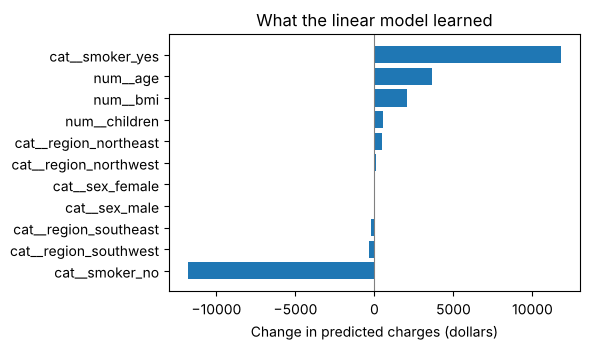

In [5]:
linear = fitted["linear regression"]
names = linear.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(linear.named_steps["model"].coef_, index=names).sort_values()

plt.figure(figsize=(6, 3.6))
plt.barh(coefs.index, coefs.values)
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Change in predicted charges (dollars)")
plt.title("What the linear model learned")
plt.tight_layout()
plt.show()

**Inspect.** The smoker coefficient exceeds $20,000; age and BMI contribute more than region. These are model associations, not causal effects.

Plot ridge residuals; structure suggests missed patterns.

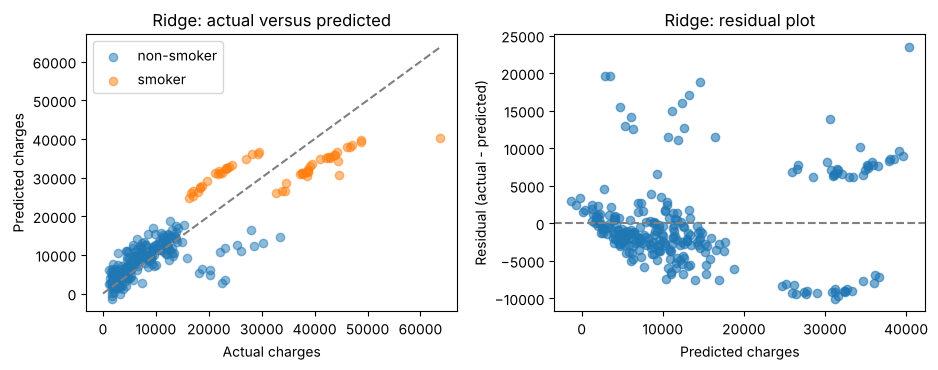

In [6]:
ridge_pred = predictions["ridge"]
residual = y_valid.to_numpy() - ridge_pred
is_smoker = (X_valid["smoker"] == "yes").to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
axes[0].scatter(y_valid[~is_smoker], ridge_pred[~is_smoker], alpha=0.5, label="non-smoker")
axes[0].scatter(y_valid[is_smoker], ridge_pred[is_smoker], alpha=0.5, label="smoker")
axes[0].plot([0, y_valid.max()], [0, y_valid.max()], linestyle="--", color="grey")
axes[0].set_xlabel("Actual charges")
axes[0].set_ylabel("Predicted charges")
axes[0].set_title("Ridge: actual versus predicted")
axes[0].legend()
axes[1].scatter(ridge_pred, residual, alpha=0.6)
axes[1].axhline(0, linestyle="--", color="grey")
axes[1].set_xlabel("Predicted charges")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Ridge: residual plot")
plt.tight_layout()
plt.show()

**Inspect.** Smoker bands suggest a smoker × BMI interaction. Shrinkage alone cannot add this missing structure.

## Part B — Regression on a time series: validate in date order
Sort two years of daily rentals by date; reserve the last 20% for validation to avoid training on future days.

In [7]:
bikes = pd.read_csv(DATA / "bike_sharing_dataset_day.csv")
bikes["dteday"] = pd.to_datetime(bikes["dteday"])
bikes = bikes.sort_values("dteday").reset_index(drop=True)

# cnt = casual + registered, so those two columns would leak the answer.
bike_cat = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
bike_num = ["temp", "atemp", "hum", "windspeed"]
X_b = bikes[bike_cat + bike_num]
y_b = bikes["cnt"]

cut = int(len(bikes) * 0.80)
print("train:", bikes["dteday"].iloc[0].date(), "to", bikes["dteday"].iloc[cut - 1].date())
print("valid:", bikes["dteday"].iloc[cut].date(), "to", bikes["dteday"].iloc[-1].date())

train: 2011-01-01 to 2012-08-06
valid: 2012-08-07 to 2012-12-31


One-hot encode calendar categories; pass numerical weather features directly to the unscaled tree model.

daily MAE: 1040.4  (mean daily demand in validation: 5897.8 )


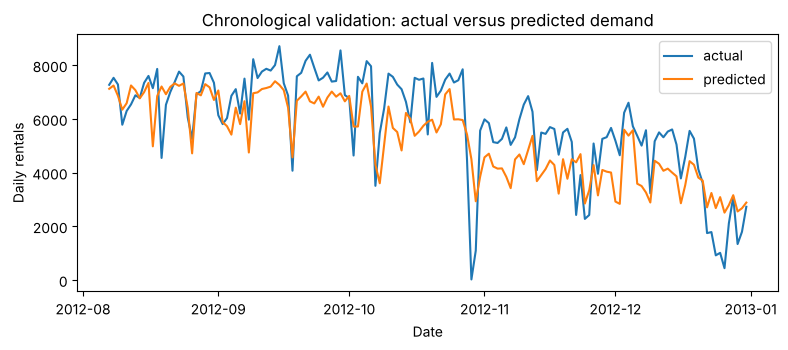

In [8]:
Xb_train, Xb_valid = X_b.iloc[:cut], X_b.iloc[cut:]
yb_train, yb_valid = y_b.iloc[:cut], y_b.iloc[cut:]
dates_valid = bikes["dteday"].iloc[cut:]

bike_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), bike_cat),
        ("num", "passthrough", bike_num),
    ])),
    ("model", RandomForestRegressor(
        n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1
    )),
])
bike_model.fit(Xb_train, yb_train)
bike_pred = bike_model.predict(Xb_valid)
print("daily MAE:", round(mean_absolute_error(yb_valid, bike_pred), 1),
      " (mean daily demand in validation:", round(yb_valid.mean(), 1), ")")

plt.figure(figsize=(8, 3.6))
plt.plot(dates_valid, yb_valid.to_numpy(), label="actual")
plt.plot(dates_valid, bike_pred, label="predicted")
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.title("Chronological validation: actual versus predicted demand")
plt.legend()
plt.tight_layout()
plt.show()

**Inspect.** The forest tracks seasonality but underpredicts peaks beyond the training-label range; it cannot extrapolate.

Repeat chronologically on 17,379 hourly rows, adding `hr`; plot one validation week.

hourly MAE: 56.5  (mean hourly demand in validation: 248.8 )


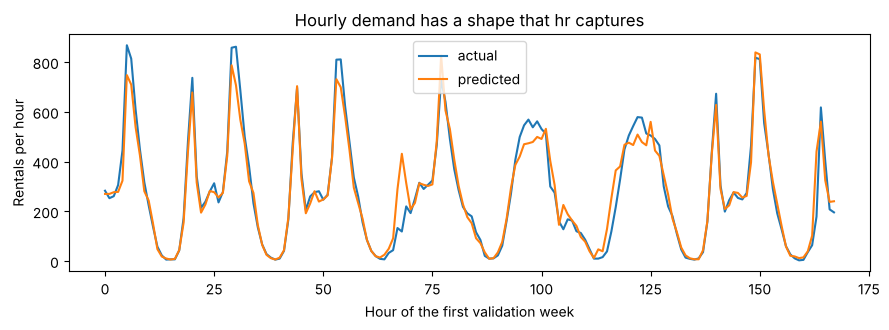

In [9]:
hourly = pd.read_csv(DATA / "bike_sharing_dataset_hour.csv")
hourly["dteday"] = pd.to_datetime(hourly["dteday"])
hourly = hourly.sort_values(["dteday", "hr"]).reset_index(drop=True)

hour_cat = bike_cat + ["hr"]
Xh = hourly[hour_cat + bike_num]
yh = hourly["cnt"]
cut_h = int(len(hourly) * 0.80)

hour_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), hour_cat),
        ("num", "passthrough", bike_num),
    ])),
    ("model", RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1
    )),
])
hour_model.fit(Xh.iloc[:cut_h], yh.iloc[:cut_h])
hour_pred = hour_model.predict(Xh.iloc[cut_h:])
print("hourly MAE:", round(mean_absolute_error(yh.iloc[cut_h:], hour_pred), 1),
      " (mean hourly demand in validation:", round(yh.iloc[cut_h:].mean(), 1), ")")

week = slice(0, 24 * 7)
plt.figure(figsize=(9, 3.4))
plt.plot(range(24 * 7), yh.iloc[cut_h:].to_numpy()[week], label="actual")
plt.plot(range(24 * 7), hour_pred[week], label="predicted")
plt.xlabel("Hour of the first validation week")
plt.ylabel("Rentals per hour")
plt.title("Hourly demand has a shape that hr captures")
plt.legend()
plt.tight_layout()
plt.show()

**Inspect.** Working days have two peaks; weekends one. Lab 8 predicts this series from 24 previous hours.

## Part C — Classification: baselines, probabilities, and the threshold
Compare logistic regression and a forest using seven passenger features, no identifiers, and stratified splits. Accuracy evaluates thresholded decisions; AUC evaluates ranking.

majority-class baseline accuracy: 0.614
logistic       accuracy=0.776 roc_auc=0.842


random_forest  accuracy=0.798 roc_auc=0.834
threshold 0.30: precision=0.64 recall=0.81
threshold 0.50: precision=0.72 recall=0.67
threshold 0.70: precision=0.90 recall=0.50


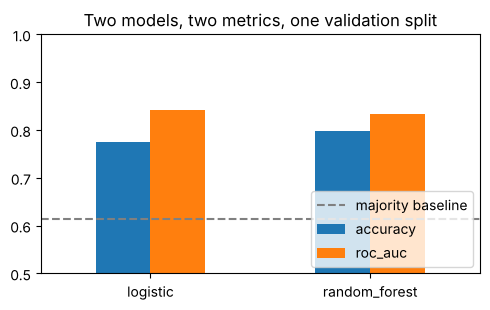

In [10]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]
X_t = titanic[features]
y_t = titanic["Survived"]

Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)
print("majority-class baseline accuracy:", round(1 - yt_valid.mean(), 3))

scores = {}
fitted_t = {}
for name, estimator in {
    "logistic": LogisticRegression(max_iter=1000),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            random_state=42),
}.items():
    pipe = Pipeline([("preprocess", make_preprocess(t_num, t_cat)), ("model", estimator)])
    pipe.fit(Xt_train, yt_train)
    fitted_t[name] = pipe
    scores[name] = {"accuracy": accuracy_score(yt_valid, pipe.predict(Xt_valid)),
                    "roc_auc": roc_auc_score(yt_valid, pipe.predict_proba(Xt_valid)[:, 1])}
    print(f"{name:14s} accuracy={scores[name]['accuracy']:.3f} "
          f"roc_auc={scores[name]['roc_auc']:.3f}")

# The same logistic model, three decision rules (the table in the notes).
prob_t = fitted_t["logistic"].predict_proba(Xt_valid)[:, 1]
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (prob_t >= threshold).astype(int)
    print(f"threshold {threshold:.2f}: precision={precision_score(yt_valid, pred_t):.2f} "
          f"recall={recall_score(yt_valid, pred_t):.2f}")

pd.DataFrame(scores).T.plot.bar(figsize=(5, 3.2), ylim=(0.5, 1.0), rot=0)
plt.axhline(1 - yt_valid.mean(), linestyle="--", color="grey", label="majority baseline")
plt.title("Two models, two metrics, one validation split")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Inspect.** Both beat the baseline, but metric rankings differ. Part D cross-validation is used to assess small differences.

For 30 tumour measurements, predict M versus B. Plot probabilities by true class; a threshold marks malignant decisions.

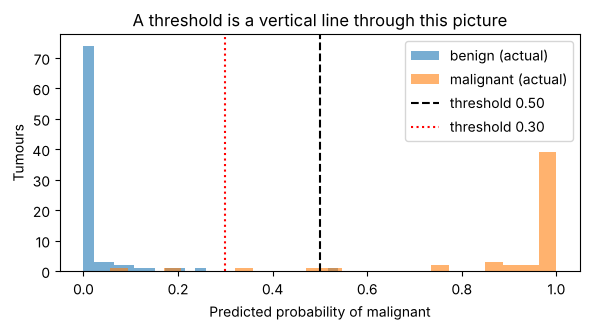

In [11]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)

cancer_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
cancer_model.fit(Xc_train, yc_train)
prob = cancer_model.predict_proba(Xc_valid)[:, 1]

plt.figure(figsize=(6, 3.4))
plt.hist(prob[yc_valid == 0], bins=25, alpha=0.6, label="benign (actual)")
plt.hist(prob[yc_valid == 1], bins=25, alpha=0.6, label="malignant (actual)")
plt.axvline(0.50, color="black", linestyle="--", label="threshold 0.50")
plt.axvline(0.30, color="red", linestyle=":", label="threshold 0.30")
plt.xlabel("Predicted probability of malignant")
plt.ylabel("Tumours")
plt.title("A threshold is a vertical line through this picture")
plt.legend()
plt.tight_layout()
plt.show()

Confusion-matrix rows are truth; columns are decisions. Precision measures correct malignant alerts; recall measures detected malignancies. Lowering the threshold increases alerts and cannot reduce recall.


threshold = 0.50
[[89  1]
 [ 4 49]]
              precision    recall  f1-score   support

           0      0.957     0.989     0.973        90
           1      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143



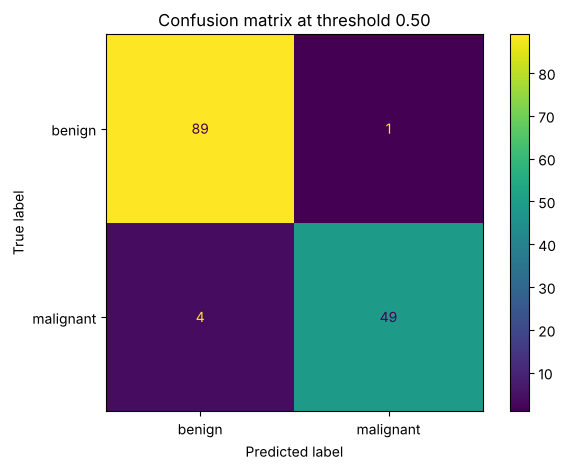


threshold = 0.30
[[89  1]
 [ 2 51]]
              precision    recall  f1-score   support

           0      0.978     0.989     0.983        90
           1      0.981     0.962     0.971        53

    accuracy                          0.979       143
   macro avg      0.979     0.976     0.977       143
weighted avg      0.979     0.979     0.979       143



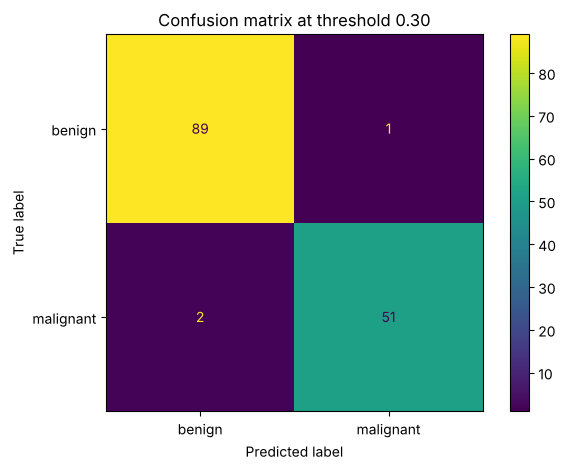

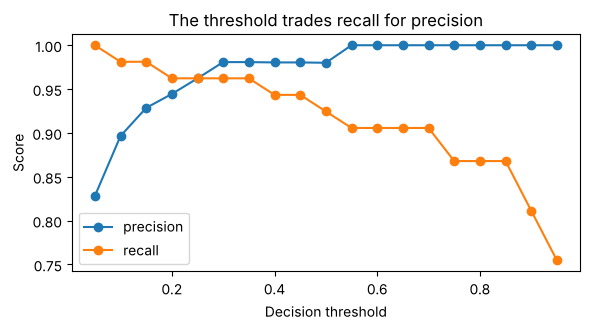

In [12]:
for threshold in [0.50, 0.30]:
    pred = (prob >= threshold).astype(int)
    print(f"\nthreshold = {threshold:.2f}")
    print(confusion_matrix(yc_valid, pred))
    print(classification_report(yc_valid, pred, digits=3))
    ConfusionMatrixDisplay.from_predictions(yc_valid, pred, display_labels=["benign", "malignant"])
    plt.title(f"Confusion matrix at threshold {threshold:.2f}")
    plt.tight_layout()
    plt.show()

thresholds = np.linspace(0.05, 0.95, 19)
precisions = [precision_score(yc_valid, (prob >= t).astype(int), zero_division=0)
              for t in thresholds]
recalls = [recall_score(yc_valid, (prob >= t).astype(int)) for t in thresholds]

plt.figure(figsize=(6, 3.4))
plt.plot(thresholds, precisions, marker="o", label="precision")
plt.plot(thresholds, recalls, marker="o", label="recall")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("The threshold trades recall for precision")
plt.legend()
plt.tight_layout()
plt.show()

ROC AUC measures ranking across classes; average precision summarizes precision–recall, emphasizing positive retrieval.

ROC AUC: 0.996
PR AUC: 0.994


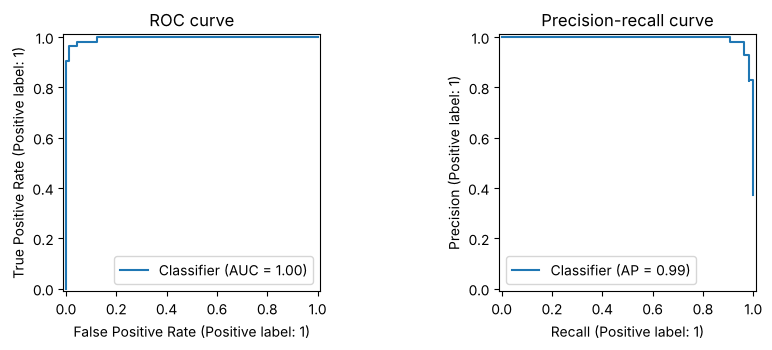

In [13]:
print("ROC AUC:", round(roc_auc_score(yc_valid, prob), 3))
print("PR AUC:", round(average_precision_score(yc_valid, prob), 3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
RocCurveDisplay.from_predictions(yc_valid, prob, ax=axes[0])
axes[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(yc_valid, prob, ax=axes[1])
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

## Part D — Tune with cross-validation, then test once
Reserve Titanic test rows. Within training data, use five-fold CV to tune `C` and `class_weight`; refit the winner on all training rows.

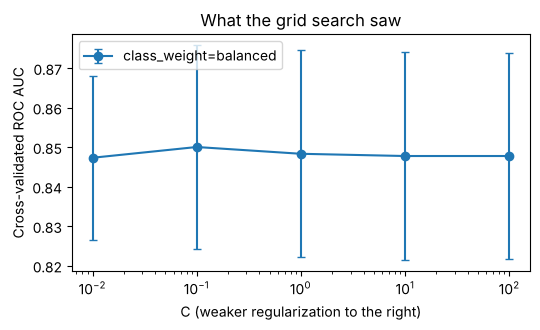

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

search = GridSearchCV(
    Pipeline([("preprocess", make_preprocess(t_num, t_cat)),
              ("model", LogisticRegression(max_iter=2000))]),
    param_grid={
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)
search.fit(X_train, y_train)

cv_table = pd.DataFrame(search.cv_results_)
plt.figure(figsize=(5.5, 3.4))
for weight, group in cv_table.groupby(cv_table["param_model__class_weight"].astype(str)):
    plt.errorbar(group["param_model__C"].astype(float), group["mean_test_score"],
                 yerr=group["std_test_score"], marker="o", capsize=3, label=f"class_weight={weight}")
plt.xscale("log")
plt.xlabel("C (weaker regularization to the right)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("What the grid search saw")
plt.legend()
plt.tight_layout()
plt.show()

**Inspect.** Fold spread exceeds many differences between settings; avoid overinterpreting small gains.

Only now is the test set touched, once.

In [15]:
test_prob = search.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_prob)

print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("final test ROC AUC:", round(test_auc, 3))

best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
cross-validated ROC AUC: 0.85
final test ROC AUC: 0.837


## Part E — Save the models and use them
Save preprocessing and estimator together with `joblib.dump`; add a card documenting inputs and evaluation.

In [16]:
final_model = search.best_estimator_
model_path = MODELS / "titanic_survival.joblib"
joblib.dump(final_model, model_path)

card = {
    "task": "predict Titanic survival (1 = survived)",
    "features": features,
    "model": "logistic regression pipeline",
    "best_parameters": search.best_params_,
    "training_rows": int(len(X_train)),
    "final_test_roc_auc": round(float(test_auc), 3),
    "decision_threshold": 0.5,
    "scikit_learn_version": sklearn.__version__,
}
(MODELS / "titanic_survival_card.json").write_text(json.dumps(card, indent=2))
size_kb = model_path.stat().st_size / 1024
print(f"saved: {model_path.name} ({size_kb:.1f} KB) and titanic_survival_card.json")

saved: titanic_survival.joblib (4.5 KB) and titanic_survival_card.json


Load the pipeline and predict new rows with matching columns, without retraining. Repeat for insurance customers differing in one feature.

In [17]:
loaded = joblib.load(model_path)
new_passengers = pd.DataFrame([
    {"Pclass": 1, "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male",   "Age": 40, "SibSp": 0, "Parch": 0, "Fare": 7.9, "Embarked": "S"},
])
new_passengers["survival_probability"] = loaded.predict_proba(new_passengers)[:, 1].round(3)
print(new_passengers)

joblib.dump(fitted["linear regression"], MODELS / "insurance_charges.joblib")
pricing = joblib.load(MODELS / "insurance_charges.joblib")
new_customer = pd.DataFrame([
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "no", "region": "southeast"},
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "yes", "region": "southeast"},
])
new_customer["predicted_charges"] = pricing.predict(new_customer).round(0)
print(new_customer)

   Pclass     Sex  Age  SibSp  Parch  Fare Embarked  survival_probability
0       1  female   29      0      0  80.0        C                 0.942
1       3    male   40      0      0   7.9        S                 0.141
   age     sex   bmi  children smoker     region  predicted_charges
0   35  female  27.5         2     no  southeast             6526.0
1   35  female  27.5         2    yes  southeast            30177.0


Run the saved passenger model from the terminal (from inside `all_experiments/`):
```
python predict_passenger.py --pclass 2 --sex female --age 30 --fare 20
```
The cell below runs the same command from the notebook.

In [18]:
!"{sys.executable}" predict_passenger.py --pclass 2 --sex female --age 30 --fare 20

survival probability: 0.805  ->  survived
(model: logistic regression pipeline, test ROC AUC 0.837)


---
## Try it yourself — Part C workflow on the heart-failure data
Label: `HeartDisease` (1 = heart disease). Column lists come from the data types with `select_dtypes`, preprocessing reuses `make_preprocess`, and results are reported at threshold 0.5.

In [19]:
heart = pd.read_csv(DATA / "heart_failure_dataset.csv")
print("shape:", heart.shape)
print(heart.head())

X_h = heart.drop(columns="HeartDisease")
y_h = heart["HeartDisease"]
h_num = X_h.select_dtypes(include="number").columns.tolist()
h_cat = X_h.select_dtypes(exclude="number").columns.tolist()
print("numeric:", h_num)
print("categorical:", h_cat)

Xh_train, Xh_valid, yh_train, yh_valid = train_test_split(
    X_h, y_h, test_size=0.25, random_state=42, stratify=y_h
)
print("majority-class baseline accuracy:", round(max(yh_valid.mean(), 1 - yh_valid.mean()), 3))

shape: (918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
numeric: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
categorical: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
majority-class baseline accura


logistic: accuracy=0.883 roc_auc=0.932
confusion matrix at threshold 0.5 (rows = truth, columns = decision):
[[ 86  17]
 [ 10 117]]



random_forest: accuracy=0.904 roc_auc=0.944
confusion matrix at threshold 0.5 (rows = truth, columns = decision):
[[ 89  14]
 [  8 119]]


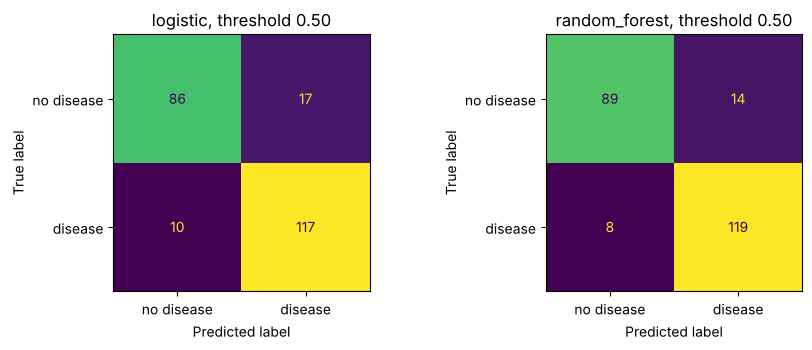

In [20]:
heart_scores = {}
heart_models = {}
for name, estimator in {
    "logistic": LogisticRegression(max_iter=1000),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            random_state=42),
}.items():
    pipe = Pipeline([("preprocess", make_preprocess(h_num, h_cat)), ("model", estimator)])
    pipe.fit(Xh_train, yh_train)
    heart_models[name] = pipe
    p = pipe.predict_proba(Xh_valid)[:, 1]
    pred = (p >= 0.5).astype(int)
    heart_scores[name] = {"accuracy": accuracy_score(yh_valid, pred),
                          "roc_auc": roc_auc_score(yh_valid, p)}
    print(f"\n{name}: accuracy={heart_scores[name]['accuracy']:.3f} "
          f"roc_auc={heart_scores[name]['roc_auc']:.3f}")
    print("confusion matrix at threshold 0.5 (rows = truth, columns = decision):")
    print(confusion_matrix(yh_valid, pred))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, pipe) in zip(axes, heart_models.items()):
    pred = (pipe.predict_proba(Xh_valid)[:, 1] >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(yh_valid, pred, ax=ax, colorbar=False,
                                            display_labels=["no disease", "disease"])
    ax.set_title(f"{name}, threshold 0.50")
plt.tight_layout()
plt.show()

**Result (validation split, 230 patients, threshold 0.5).**

| model | accuracy | ROC AUC | missed disease (FN) | false alarms (FP) |
|---|---|---|---|---|
| majority baseline | 0.552 | – | – | – |
| logistic regression | 0.883 | 0.932 | 10 | 17 |
| random forest | 0.904 | 0.944 | 8 | 14 |

`select_dtypes` found 6 numeric columns (Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak) and 5 text columns (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope). Both models are far above the 55% majority baseline. Here the forest wins on both metrics, unlike Titanic where the two metrics disagreed, though a 2-point gap on one split should still be confirmed with cross-validation as in Part D. At threshold 0.5 the forest still misses 8 of 127 patients who have heart disease; if missed cases are the costlier error, the threshold should be lowered as discussed in the memo below.

*Note:* `FastingBS` is 0/1, so `select_dtypes` treats it as numeric; it is still fine after scaling. Some `Cholesterol` values are 0, which is physically impossible and almost certainly means "not recorded". A further improvement would be to replace those with NaN so the median imputer handles them.

---
## Decision memo — choosing a threshold when missed positives cost more

In [21]:
# Part C validation evidence: breast-cancer model at several thresholds
rows = []
for t in [0.50, 0.40, 0.30, 0.20, 0.10]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yc_valid, pred).ravel()
    rows.append({"threshold": t, "missed malignant (FN)": fn, "false alarms (FP)": fp,
                 "recall": round(recall_score(yc_valid, pred), 3),
                 "precision": round(precision_score(yc_valid, pred), 3)})
memo_table = pd.DataFrame(rows)
memo_table

,threshold,missed malignant (FN),false alarms (FP),recall,precision
0,0.5,4,1,0.925,0.980
1,0.4,3,1,0.943,0.980
2,0.3,2,1,0.962,0.981
3,0.2,2,3,0.962,0.944
4,0.1,1,6,0.981,0.897


**Memo — threshold for the breast-cancer screening model**

*Situation.* Missing a malignant tumour (false negative) means a patient goes untreated, while a false alarm means an extra test or biopsy. Missed positives therefore cost much more than false alarms, so the default threshold of 0.50 is not automatically the right one.

*Evidence (Part C validation set: 143 tumours, 53 malignant).*
- At **0.50**: 4 malignant tumours missed, 1 false alarm (recall 0.925, precision 0.980).
- At **0.30**: only 2 missed, still 1 false alarm (recall 0.962, precision 0.981).
- At **0.10**: 1 missed, but false alarms rise to 6 (recall 0.981, precision 0.897).

The confusion matrix shows what moves: lowering the threshold shifts tumours from the bottom-left cell (missed malignant) to the bottom-right (caught malignant), and eventually some benign tumours move from top-left into top-right (false alarms). As the notes say, recall can only go up or stay the same as the threshold falls.

*Decision.* Use **threshold 0.30**. It halves missed cancers (4 → 2) at no extra cost in false alarms on this validation set, so it is a strict improvement over 0.50. Going lower, to 0.10, catches one more cancer but adds five false alarms; that trade is worth it only if follow-up tests are cheap and available. The Titanic table in Part C shows the same pattern: dropping the threshold from 0.50 to 0.30 raised recall from 0.67 to 0.81 while precision fell from 0.72 to 0.64.

*Caveat.* These counts come from a single small validation split, so differences of one or two tumours are noisy. Before deployment the threshold should be confirmed with cross-validation and then checked once on an untouched test set.

---
## Check your understanding

**1. Why is logistic regression called a linear classifier even though it outputs a nonlinear sigmoid probability?**

Logistic regression computes a linear score z = w·x + b and passes it through the sigmoid, p = 1 / (1 + e^(−z)). The sigmoid is nonlinear, but it is monotonic, so p ≥ 0.5 exactly when z ≥ 0 (and any threshold on p equals some threshold on z). The decision boundary w·x + b = constant is therefore a straight line (a hyperplane) in feature space. "Linear" describes that boundary, not the shape of the probability curve.

**2. Why should the probability model and the operational classification threshold be treated as separate objects?**

The model's job is to estimate *how likely* each case is to be positive; that is a statistical question answered by training and measured by ranking metrics such as ROC AUC. The threshold turns probabilities into *actions*, and the right threshold depends on costs and capacity (how bad a missed cancer is compared with an unnecessary biopsy, how many alerts staff can handle). Those business or clinical considerations can change without retraining. Keeping them separate lets us retune the threshold, as in the memo above, while the same saved model is reused. Fusing them would mean retraining whenever priorities change, and would hide that accuracy at 0.5 is just one choice.

**3. What changes when binary logistic regression is extended to a multiclass softmax model?**

- Instead of one weight vector there is one per class (K score functions z_k = w_k·x + b_k).
- The sigmoid is replaced by **softmax**: p_k = e^(z_k) / Σ_j e^(z_j), giving K probabilities that are all positive and sum to 1.
- The loss becomes categorical cross-entropy (log loss over K classes) instead of binary cross-entropy.
- The prediction is usually the class with the highest probability (argmax), so there is no longer a single 0.5 threshold. Decision rules use per-class costs or thresholds instead.
- Boundaries between any two classes are still linear, so the feature space is divided into K linear regions.